# 05 - Words the model has never seen: copy mechanism (M3) and BPE

**Goal of this notebook.** Notebook 02 found the biggest limit of the models so far: **38% of the dev queries contain a word that is not in the
vocabulary**. A model that writes words from the vocabulary can only write `<unk>` for such a word, which is never correct, so its score cannot
exceed about 62%. Here are two ways to remove this limit:

| Way | Idea |
|---|---|
| **Copy mechanism (M3)** | Every word to write is in the input (a column name, or a value of the question). Let the decoder *copy* it from the input. |
| **BPE** | Build the vocabulary from *pieces* of words. Any word can then be written, piece by piece. |

Files written by this notebook:

| File | Role |
|---|---|
| `src/t2s/data/copy_codec.py` | the copy codec: temporary ids for unknown words |
| `src/t2s/models/copy.py` | the pointer-generator: the decoder that can copy, and the model M3 |
| `src/t2s/data/bpe.py` | learning the pieces (BPE), cutting words, and the BPE codec |
| `configs/m3.yaml`, `configs/m2_bpe.yaml` | the settings of M3 and of M2 with BPE |

Tools from earlier notebooks that are used here:

| Tool | What it does | Where it is explained |
|---|---|---|
| `PlainCodec`, `Encoded`, `collate`, `build_vocab`, `Vocab` | the plain codec (a word is a token) and the batches | notebook 02, section 4 |
| `source_tokens`, `target_tokens`, `parse_target` | the format of the input and output | notebook 02, section 2 |
| `AttentionDecoder`, `AttentionSeq2Seq` | attention, which M3 extends | notebook 04, section 2 |
| `train`, `load_checkpoint`, `build_codec`, `build_model` | training; the codec and the model are chosen from the config | notebook 03, section 8 |
| `decode_examples`, `score`, `SqliteExecutor` | generation and the metrics | notebook 03, sections 1 and 7 |

## Setup



In [4]:
import json, os, sys
from pathlib import Path

NOTEBOOK_NUMBER = 5
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/text2sql")
    CODE = "/content/code"                                      # where the notebooks write their code
    DATA_ROOT = "/content/data"                                 # the dataset (downloaded in each session)
    CKPT_DIR = "/content/drive/MyDrive/text2sql_checkpoints"    # the saved models
else:
    PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    CODE, DATA_ROOT, CKPT_DIR = str(PROJECT / "code"), str(PROJECT / "data"), str(PROJECT / "checkpoints")
os.chdir(PROJECT)   # the results are saved in the folder "results" of the project
os.makedirs(CKPT_DIR, exist_ok=True)


def rebuild_code(before):
    """Write again the code files of the notebooks 01 ... before-1 (their writefile cells)."""
    for path in sorted((PROJECT / "notebooks").glob("[0-9][0-9]_*.ipynb")):
        if int(path.name[:2]) >= before:
            continue
        for cell in json.loads(path.read_text())["cells"]:
            source = "".join(cell["source"])
            if cell["cell_type"] != "code" or not source.startswith("%%writefile"):
                continue
            first_line, _, body = source.partition("\n")
            words = first_line.split()
            target = Path(words[-1].replace("{CODE}", CODE))
            target.parent.mkdir(parents=True, exist_ok=True)
            with open(target, "a" if words[1] == "-a" else "w") as f:
                f.write(body if body.endswith("\n") else body + "\n")


for folder in ["src/t2s/data", "src/t2s/models", "src/t2s/decoding", "src/t2s/eval", "scripts", "configs"]:
    os.makedirs(f"{CODE}/{folder}", exist_ok=True)
rebuild_code(NOTEBOOK_NUMBER)
for package in ["src/t2s", "src/t2s/data", "src/t2s/models", "src/t2s/decoding", "src/t2s/eval"]:
    Path(f"{CODE}/{package}/__init__.py").touch()
sys.path.insert(0, f"{CODE}/src")

Mounted at /content/drive


In [5]:
import json
from pathlib import Path
import torch
from t2s.data.download import download_wikisql
from t2s.data.wikisql import load_split, db_path
from t2s.eval.executor import SqliteExecutor

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

data_dir = download_wikisql(DATA_ROOT)
splits = {name: load_split(data_dir, name) for name in ["train", "dev"]}
dev_executor = SqliteExecutor(db_path(data_dir, "dev"))
Path("results/phase5_copy_bpe").mkdir(parents=True, exist_ok=True)

device: cpu


# Part A - The copy mechanism (M3)

## A1. The idea

Look at a question and its query:

```
Question: how many times is the fuel propulsion is cng?
Query   : <sel> <agg_count> fleet series ( quantity ) <where> fuel propulsion <eq> cng
```

Every word the decoder has to write (`fuel`, `propulsion`, `cng`, ...) is **somewhere in the input**: the column names are in the part of the input
that lists the columns, and the value is in the question. If the decoder could write `cng` by *pointing at* the input word `cng`, it would not need
`cng` to be in its vocabulary.

**Two ways to write a word.** At each step the decoder can

- **generate** a word of the vocabulary (as before), or
- **copy** a word of the input, by choosing a position.

A number `p_gen` between 0 and 1 says how much it relies on the first way. The decoder computes it at each step. For a structure token such as
`<where>`, `p_gen` should be close to 1 (generate); for a value, it should be close to 0 (copy). The probability of copying the position `i` is the
**attention weight** of position `i` (notebook 04): the attention, which already says where to look, also says what to copy. The final probability of a
word is the sum of the two ways:

`P(word) = p_gen * P_vocabulary(word) + (1 - p_gen) * (sum of the attention weights of the input positions that hold this word)`

This is the *pointer-generator* of See, Liu and Manning (2017).

**A problem to solve first: unknown words need an id.** To say "this output word is the same as that input word", the unknown word needs an identity.
But with the plain codec all the unknown words become `<unk>`, with the same id. The solution is a **temporary id**: in each input, the first
unknown word gets the id `V`, the second `V + 1`, and so on (`V` is the size of the vocabulary). The same word has the same temporary id in the input
and in the output.

**The description** is in the docstring. The imports use the plain codec of notebook 02: the copy codec *inherits* from it (the vocabulary, `build`,
`state` are the same) and only changes the encoding and the decoding.

In [6]:
%%writefile {CODE}/src/t2s/data/copy_codec.py
"""The copy codec: a word that is not in the vocabulary can still be written, by copying it.

With the plain codec, an unknown word becomes <unk> and the model can never write it. Here an
unknown word of the input gets a temporary id for this input only: the first unknown word is
V, the second is V + 1, and so on (V is the size of the vocabulary). The same word has the
same temporary id in the input and in the output, so the model can write it by copying it
from the input (see `models/copy.py`). The temporary ids are turned back into words when the
output is decoded.
"""

from dataclasses import dataclass

from t2s.data.dataset import Encoded, PlainCodec
from t2s.data.format import EOS, SOS, source_tokens, target_tokens
from t2s.data.wikisql import Example




Writing /content/code/src/t2s/data/copy_codec.py


**`EncodedCopy`** is an encoded example like `Encoded` (the input ids and the output ids), plus `oov`: the list of the unknown words of this input.
The word number `k` of this list has the id `V + k`.

In [7]:
%%writefile -a {CODE}/src/t2s/data/copy_codec.py
@dataclass(frozen=True)
class EncodedCopy(Encoded):
    oov: tuple[str, ...]  # the unknown words of this input; the word k has the id V + k




Appending to /content/code/src/t2s/data/copy_codec.py


**`CopyCodec`** is the codec of the copy mechanism.

In [8]:
%%writefile -a {CODE}/src/t2s/data/copy_codec.py
class CopyCodec(PlainCodec):
    kind = "copy"



Appending to /content/code/src/t2s/data/copy_codec.py


**`encode`** turns an example into ids. `input_id` gives a word its id in the vocabulary, or, if it is unknown, a temporary id (the word is added to
the list `oov` the first time). `output_id` does the same for the output words, but never creates a new temporary id: an output word that is not in
the input (for example, one that was cut by the length limit) cannot be copied, so it stays `<unk>`.

In [9]:
%%writefile -a {CODE}/src/t2s/data/copy_codec.py
    def encode(self, ex: Example, max_src_len: int = 128, max_tgt_len: int = 64) -> EncodedCopy:
        vocab = self.vocab
        oov: list[str] = []

        def input_id(word: str) -> int:
            if word in vocab.stoi:
                return vocab.stoi[word]
            if word not in oov:
                oov.append(word)
            return len(vocab) + oov.index(word)

        def output_id(word: str) -> int:
            if word in vocab.stoi:
                return vocab.stoi[word]
            if word in oov:  # an unknown word of the input: its temporary id
                return len(vocab) + oov.index(word)
            return vocab.unk_id  # a word that is not in the input (for example, cut by the length limit)

        src = [input_id(w) for w in source_tokens(ex.question, ex.header)[:max_src_len]]
        words = target_tokens(ex.query, ex.header)[: max_tgt_len - 2]
        tgt = [vocab.stoi[SOS], *[output_id(w) for w in words], vocab.stoi[EOS]]
        return EncodedCopy(src, tgt, tuple(oov))



Appending to /content/code/src/t2s/data/copy_codec.py


**`decode`** turns output ids back into words. An id smaller than `V` is a word of the vocabulary; an id from `V` on is a temporary id, and the
word is found in the list `oov` of this input.

In [10]:
%%writefile -a {CODE}/src/t2s/data/copy_codec.py
    def decode(self, ids: list[int], encoded: EncodedCopy | None = None) -> list[str]:
        tokens = []
        for i in ids:
            if i < len(self.vocab):
                tokens.append(self.vocab.itos[i])
            elif encoded is not None and i - len(self.vocab) < len(encoded.oov):
                tokens.append(encoded.oov[i - len(self.vocab)])
            else:
                tokens.append("<unk>")
        return tokens


Appending to /content/code/src/t2s/data/copy_codec.py


### A2. The codec on an example

I look for a dev example that contains unknown words.

In [11]:
from t2s.data.copy_codec import CopyCodec
from t2s.data.format import source_tokens, target_tokens

copy_codec = CopyCodec.build(splits["train"], {"min_freq": 2})
V = len(copy_codec.vocab)

ex = next(e for e in splits["dev"] if len(copy_codec.encode(e).oov) >= 2 and e.query.conds)
encoded = copy_codec.encode(ex)
print("question :", ex.question.strip())
print("gold     :", ex.query.to_sql(ex.header))
print("unknown words of this input (temporary ids V, V+1, ...):", {V + k: w for k, w in enumerate(encoded.oov)})
print()
print("input ids :", [i if i < V else f"[{i}]" for i in encoded.src])
print("output ids:", [i if i < V else f"[{i}]" for i in encoded.tgt])
print("decoded   :", " ".join(copy_codec.decode(encoded.tgt[1:-1], encoded)))

import numpy as np
n_unknown = [len(copy_codec.encode(e).oov) for e in splits["dev"]]
print(f"\ndev inputs with at least one unknown word: {np.mean([n > 0 for n in n_unknown]):.1%}; unknown words per input: "
      f"mean {np.mean(n_unknown):.2f}, max {max(n_unknown)}")

question : When did Jacques Chirac stop being a G8 leader?
gold     : SELECT Ended time as senior G8 leader FROM table WHERE Person = 'Jacques Chirac'
unknown words of this input (temporary ids V, V+1, ...): {15962: 'chirac', 15963: 'g8'}

input ids : [37, 101, 3925, '[15962]', 2801, 270, 28, '[15963]', 676, 19, 4, 5, 665, 351, 99, 519, 21, 177, 319, 1797, 5, 1400, 62, 99, 924, '[15963]', 676, 5, 775, 62, 99, 924, '[15963]', 676, 5, 643, 5, 351]
output ids: [2, 6, 9, 775, 62, 99, 924, '[15963]', 676, 7, 643, 15, 3925, '[15962]', 3]
decoded   : <sel> <agg_none> ended time as senior g8 leader <where> person <eq> jacques chirac

dev inputs with at least one unknown word: 41.6%; unknown words per input: mean 0.68, max 10


**What I observe.** The unknown words of the input get the temporary ids `V`, `V + 1`, ... (shown in brackets). The output uses **the same ids** for the
same words, and decoding gives back the exact words. In the dev set, **41.6% of the inputs contain at least one unknown word** (0.68 on average, up
to 10), so the copy mechanism has plenty to do.

## A3. The model: a pointer-generator

**The idea** is in the docstring: two ways to write a word, and the formula for the final probability. The model returns **log-probabilities**; the
training loop is the same as for the other models (the cross-entropy of log-probabilities that add up to 1 is the negative log-likelihood).

In [12]:
%%writefile {CODE}/src/t2s/models/copy.py
"""The copy mechanism (model M3): a pointer-generator.

At each step the decoder has two ways to write a word:

    generate  choose a word of the vocabulary          probability p_gen
    copy      choose a position of the input           probability 1 - p_gen

The probability of copying the position i is the attention weight of position i, so the
attention that tells the decoder where to look also tells it what to copy. The probability of
writing a word is the sum of the two ways:

    P(word) = p_gen * P_vocabulary(word) + (1 - p_gen) * (sum of the attention weights of the
                                                           input positions that hold this word)

A word that is not in the vocabulary has no entry in P_vocabulary, but it has a temporary id
(see `data/copy_codec.py`), so it gets a probability from the copy part. p_gen is computed from
the decoder state, the context and the embedding of the previous word, and is a number between 0
and 1: close to 1 for the structure tokens (<where>, <eq> ...), close to 0 for a word to copy.

The model returns log-probabilities. The training loop is the one of the other models: the
cross-entropy of log-probabilities that sum to 1 is the negative log-likelihood.
"""

import torch
import torch.nn.functional as F
from torch import nn

from t2s.models.attention import AttentionDecoder, AttentionSeq2Seq




Writing /content/code/src/t2s/models/copy.py


**`CopyDecoder.__init__`.** It is the attention decoder of notebook 04 plus `gate`, a small linear layer that computes `p_gen` from the decoder
state, the context vector and the embedding of the previous word. `last_gate` keeps the last `p_gen` for the analysis.

In [13]:
%%writefile -a {CODE}/src/t2s/models/copy.py
class CopyDecoder(AttentionDecoder):
    def __init__(
        self,
        vocab_size: int,
        emb_dim: int,
        hidden: int,
        num_layers: int,
        dropout: float,
        pad_id: int,
        enc_dim: int,
        unk_id: int,
    ):
        super().__init__(vocab_size, emb_dim, hidden, num_layers, dropout, pad_id, enc_dim)
        self.vocab_size = vocab_size
        self.unk_id = unk_id
        self.gate = nn.Linear(hidden + enc_dim + emb_dim, 1)  # computes p_gen
        self.last_gate = None  # p_gen of the last step, kept for the analysis



Appending to /content/code/src/t2s/models/copy.py


**`CopyDecoder.step`.** The first part is the attention decoder. Then:

1. `vocab_probs`: the probabilities of the words of the vocabulary (a softmax over `V` words).
2. `p_gen`: the gate, between 0 and 1.
3. `F.pad(p_gen * vocab_probs, (0, n_oov))` makes room, after the `V` words, for the unknown words of this batch.
4. `scatter_add` adds the probability of copying: for each input position, the attention weight, multiplied by `1 - p_gen`, is added to the id of the
   word at this position. If a word appears at several positions, their weights add up.
5. The result is a probability for every word of the **extended vocabulary** (the `V` words and the unknown words). The logarithm is returned.

A word that was written by copying has a temporary id, which is not in the vocabulary, so at the start of the step such a previous word is fed back
to the decoder as `<unk>`.

In [14]:
%%writefile -a {CODE}/src/t2s/models/copy.py
    def step(self, token, state, memory):
        """One decoding step. Returns the log-probabilities of the next word.

        memory: (encoder states, keys, mask, ids of the input words, number of unknown words).
        The ids of the input words are the temporary ones, so an unknown word can be copied.
        """
        enc_states, keys, mask, src_ids, n_oov = memory
        # A word written by copying is not in the vocabulary: it is fed back as <unk>.
        token = token.masked_fill(token >= self.vocab_size, self.unk_id)
        h, c = state
        embedded = self.dropout(self.embedding(token))
        x = embedded
        new_h, new_c = [], []
        for layer, cell in enumerate(self.cells):
            h_layer, c_layer = cell(x, (h[layer], c[layer]))
            new_h.append(h_layer)
            new_c.append(c_layer)
            x = self.dropout(h_layer)

        decoder_state = new_h[-1]
        context, weights = self.attention(decoder_state, enc_states, keys, mask)
        attentional = torch.tanh(self.combine(torch.cat([decoder_state, context], dim=-1)))

        vocab_probs = torch.softmax(self.out(self.dropout(attentional)), dim=-1)  # (B, V)
        p_gen = torch.sigmoid(self.gate(torch.cat([decoder_state, context, embedded], dim=-1)))  # (B, 1)

        probs = F.pad(p_gen * vocab_probs, (0, n_oov))  # room for the unknown words: (B, V + n_oov)
        probs = probs.scatter_add(1, src_ids, (1 - p_gen) * weights)  # add the copy probabilities

        self.last_weights = weights
        self.last_gate = p_gen
        return torch.log(probs + 1e-12), (torch.stack(new_h), torch.stack(new_c))




Appending to /content/code/src/t2s/models/copy.py


**`CopySeq2Seq`** is the model M3. It inherits from `AttentionSeq2Seq` (notebook 04): the training loop and the starting state are the same, and only the
decoder is replaced.

In [15]:
%%writefile -a {CODE}/src/t2s/models/copy.py
class CopySeq2Seq(AttentionSeq2Seq):
    """Model M3: M2 (attention) with the copy mechanism."""

    def __init__(
        self,
        vocab_size: int,
        pad_id: int,
        emb_dim: int = 256,
        hidden: int = 256,
        num_layers: int = 1,
        bidirectional: bool = True,
        dropout: float = 0.3,
        unk_id: int = 1,
    ):
        super().__init__(vocab_size, pad_id, emb_dim, hidden, num_layers, bidirectional, dropout)
        self.vocab_size = vocab_size
        self.unk_id = unk_id
        self.decoder = CopyDecoder(
            vocab_size, emb_dim, hidden, num_layers, dropout, pad_id, self.encoder.out_dim, unk_id
        )



Appending to /content/code/src/t2s/models/copy.py


**`init_decode`** reads the input. The input holds temporary ids, which the embedding table does not know, so the encoder reads the unknown words as
`<unk>`. The *original* ids are kept in the memory, because the decoder needs them to copy. `n_oov` is the number of temporary ids in the batch.

In [16]:
%%writefile -a {CODE}/src/t2s/models/copy.py
    def init_decode(self, src: torch.Tensor, src_len: torch.Tensor):
        """`src` holds the temporary ids; the encoder reads unknown words as <unk>."""
        n_oov = max(int(src.max()) - self.vocab_size + 1, 0)
        enc_states, enc_state = self.encoder(src.masked_fill(src >= self.vocab_size, self.unk_id), src_len)
        positions = torch.arange(src.size(1), device=src.device)
        mask = positions[None, :] < src_len.to(src.device)[:, None]
        keys = self.decoder.attention.keys(enc_states)
        return self._decoder_state(enc_state), (enc_states, keys, mask, src, n_oov)


Appending to /content/code/src/t2s/models/copy.py


### A4. Checking the mechanism

Three checks before training: the probabilities add up to 1 over the extended vocabulary; the gate really controls the two ways (with `p_gen = 0`
only the words of the input can be written, with `p_gen = 1` only the vocabulary); and, the most important, the model can **learn to write words that
are not in the vocabulary**.

In [17]:
import torch.nn.functional as F
from t2s.models.copy import CopySeq2Seq
from t2s.data.dataset import collate
from t2s.models.seq2seq import count_parameters

vocab = copy_codec.vocab
batch = collate([copy_codec.encode(e) for e in splits["train"][:64]], vocab.pad_id)
batch = {k: v.to(device) for k, v in batch.items()}

torch.manual_seed(0)
model = CopySeq2Seq(len(vocab), vocab.pad_id, unk_id=vocab.unk_id, emb_dim=256, hidden=256, dropout=0.0).to(device)
log_probs = model(batch["src"], batch["src_len"], batch["tgt_in"])
n_oov = int(batch["src"].max()) - len(vocab) + 1
print(f"output scores: {tuple(log_probs.shape)}  (the vocabulary has {len(vocab)} words, plus {n_oov} unknown words in this batch)")
print("probabilities add up to 1:", torch.allclose(log_probs.exp().sum(dim=-1), torch.ones_like(log_probs[..., 0]), atol=1e-4))
from t2s.models.attention import AttentionSeq2Seq
m2 = AttentionSeq2Seq(len(vocab), vocab.pad_id, emb_dim=256, hidden=256, dropout=0.0)
print(f"parameters: M2 {count_parameters(m2):,}   M3 {count_parameters(model):,}   (the gate adds {count_parameters(model) - count_parameters(m2):,})")

# The gate controls the two ways of writing a word.
in_input = torch.zeros(batch["src"].size(0), log_probs.size(-1), device=device)
in_input.scatter_(1, batch["src"], 1.0)           # 1 for the words that are in the input of each example
with torch.no_grad():
    for p_gen, bias in [("0 (always copy)", -30.0), ("1 (always generate)", 30.0)]:
        model.decoder.gate.weight.zero_()
        model.decoder.gate.bias.fill_(bias)
        probs = model(batch["src"], batch["src_len"], batch["tgt_in"]).exp()
        on_input = (probs * in_input[:, None, :]).sum(-1).mean()
        on_unknown = probs[..., len(vocab):].sum(-1).mean()
        print(f"p_gen = {p_gen}: probability on the words of the input {on_input:.2f}, on the unknown words {on_unknown:.2f}")

output scores: (64, 25, 15966)  (the vocabulary has 15962 words, plus 4 unknown words in this batch)
probabilities add up to 1: True
parameters: M2 14,509,402   M3 14,510,427   (the gate adds 1,025)
p_gen = 0 (always copy): probability on the words of the input 1.00, on the unknown words 0.01
p_gen = 1 (always generate): probability on the words of the input 0.00, on the unknown words 0.00


**What I observe.** The scores cover the vocabulary plus the unknown words of the batch, and the probabilities add up to 1. With `p_gen = 0` (always
copy) **all** the probability (1.00) is on words of the input; with `p_gen = 1` (always generate) almost none of it is (the untrained vocabulary
distribution spreads over all the words), and **none** goes to the unknown words, which only the copy path can write. So the two ways work as
described. M3 has only 1,025 more parameters than M2: the gate.

In [ ]:
# Can the model memorize one batch, including the words that are not in the vocabulary?
torch.manual_seed(0)
model = CopySeq2Seq(len(vocab), vocab.pad_id, unk_id=vocab.unk_id, emb_dim=256, hidden=256, dropout=0.0).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=3e-3)
unknown_in_target = int((batch["tgt_out"] >= len(vocab)).sum())
print("tokens of the target that are not in the vocabulary:", unknown_in_target)
for step in range(151):
    scores = model(batch["src"], batch["src_len"], batch["tgt_in"])
    loss = F.cross_entropy(scores.reshape(-1, scores.size(-1)), batch["tgt_out"].reshape(-1), ignore_index=vocab.pad_id)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if step % 50 == 0:
        print(f"step {step:3d}  loss {loss.item():.3f}")

tokens of the target that are not in the vocabulary: 22
step   0  loss 6.593
step  50  loss 0.059
step 100  loss 0.003
step 150  loss 0.001


**What I observe.** The batch contains target words that are not in the vocabulary, and the loss still goes to nearly zero: the only way to write them
is to copy them, so the copy path works.

## A5. Training M3

M3 uses the copy codec (`codec: copy`) and the copy model (`type: copy`); everything else is the same as for M2, so the comparison M2 / M3 changes one
thing.

**`configs/m3.yaml`:** the settings of M3 (see notebook 03, section 9, for the meaning of each one).

In [18]:
%%writefile {CODE}/configs/m3.yaml
# M3: M2 (attention) with the copy mechanism. The data are encoded with the copy codec,
# so a word that is not in the vocabulary can be written by copying it from the input.
name: m3
seed: 0

data:
  codec: copy
  min_freq: 2
  max_src_len: 128
  max_tgt_len: 64

model:
  type: copy
  emb_dim: 256
  hidden: 256
  num_layers: 1
  bidirectional: true
  dropout: 0.3

train:
  epochs: 25
  batch_size: 64
  lr: 0.001
  weight_decay: 0.0
  clip: 1.0
  teacher_forcing: 1.0
  patience: 4
  lr_patience: 1
  eval_subset: 1000


Writing /content/code/configs/m3.yaml


In [ ]:
import yaml
from t2s.train import train

cfg_m3 = yaml.safe_load((Path(CODE) / "configs/m3.yaml").read_text())
result_m3 = train(cfg_m3, data_dir, results_dir="results", ckpt_dir=CKPT_DIR, resume=True)

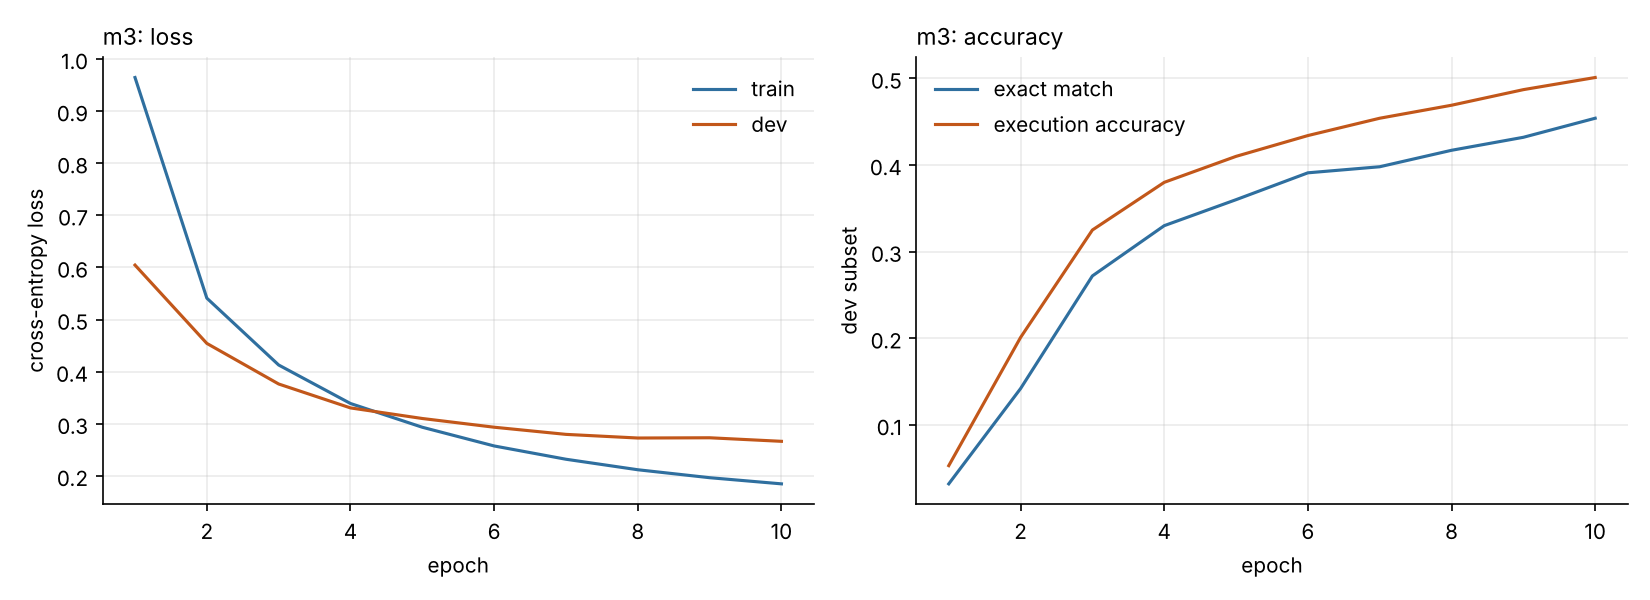

In [27]:
from IPython.display import Image
Image("results/m3/curves.png")

The model learns well and is not overfitting. Train loss goes from 0.96 to 0.19 and dev loss goes from 0.60 to 0.27. The dev line flattens after epoch 8 while the train line keeps going down. The gap is small (0.19 vs 0.27), so overfitting is mild at epoch 10.

Dev loss is lower than train loss in epochs 1 to 3. Train loss is averaged over the whole epoch while the model is still learning, and dropout 0.3 is on during training and off at evaluation. So this is normal.

Accuracy was still rising at epoch 10. Exact match on the 1000-example dev subset went from 3% to 45%, and execution accuracy to 50%. The best epoch was the last one, so the model had not finished learning. I used only 10 epochs because of the compute limit, and 25 epochs would probably give a higher score.
Execution accuracy stays above exact match. Some queries are written in a different way from the gold query but return the same answer.

On the full dev set, M3 reaches 49.3% exact match and 57.1% execution accuracy. M2 reached 40.2% and 44.9% after 25 epochs. M3 is better with fewer than half the epochs.
Limit: the 10-epoch budget is shorter than the 25 epochs of M2, so the comparison favours M2 in training time and M3 still wins.

### A6. When does M3 copy?

I follow M3 step by step on a dev question that contains unknown words, and print, for each written word, whether the word is in the vocabulary, and the
value of `p_gen`. A low `p_gen` means that the word is copied from the input (even a word that is also in the vocabulary).

In [28]:
import pandas as pd
from t2s.train import load_checkpoint

model, codec, cfg = load_checkpoint(f"{CKPT_DIR}/m3/best.pt", device)
ex = next(e for e in splits["dev"] if len(codec.encode(e).oov) >= 2 and e.query.conds)
encoded = codec.encode(ex)
print("question:", ex.question.strip())
print("gold    :", ex.query.to_sql(ex.header))

src = torch.tensor([encoded.src], device=device)
src_len = torch.tensor([len(encoded.src)], device=device)
rows, token = [], torch.tensor([codec.vocab.sos_id], device=device)
model.eval()
with torch.no_grad():
    state, memory = model.init_decode(src, src_len)
    for _ in range(40):
        log_probs, state = model.step(token, state, memory)
        token = log_probs.argmax(-1)
        i = token.item()
        rows.append({"written": codec.decode([i], encoded)[0],
                     "word in the vocabulary": "no" if i >= len(codec.vocab) else "yes",
                     "p_gen": round(model.decoder.last_gate.item(), 2)})
        if i == codec.vocab.eos_id:
            break
pd.DataFrame(rows)

question: When did Jacques Chirac stop being a G8 leader?
gold    : SELECT Ended time as senior G8 leader FROM table WHERE Person = 'Jacques Chirac'


,written,word in the vocabulary,p_gen
0,<sel>,yes,1.00
1,<agg_none>,yes,1.00
2,entered,yes,0.00
3,office,yes,0.00
4,<where>,yes,0.64
5,person,yes,0.00
6,<eq>,yes,1.00
7,g8,no,0.00
8,<eos>,yes,0.76


**What I observe.** Structure tokens are generated. <sel>, <agg_none> and <eq> have p_gen = 1.00. They never appear in the question, so the model writes them from its vocabulary. <where> (0.64) and <eos> (0.76) are also mostly generated, but the model is less sure.

Words from the input are copied. entered, office and person have p_gen = 0.00. They are column names from the input, and the model copies them with the attention weights.

An unknown word is copied. g8 is not in the vocabulary (the column “word in the vocabulary” says “no”), and its p_gen is 0.00. This is the situation the copy mechanism was made for. M2 could only write <unk> here, and M3 wrote the real word.

The gate does what I expected: it is close to 1 for structure and close to 0 for words taken from the input.

The prediction is still wrong. The model chose the column entered office instead of ended time as senior g8 leader (the question says “stop being”). It also copied g8 as the value, where the gold value is Jacques Chirac. So copying solves the problem of unknown words, but the model can still choose the wrong column or the wrong span of the question.

# Part B - BPE: a vocabulary of pieces of words

## B1. The idea

A vocabulary of whole words cannot write a word it has never seen. **Byte-pair encoding (BPE)** (Sennrich et al., 2016) builds a vocabulary of
*pieces* instead:

1. Start with every word cut into its characters. The last character carries an end marker `</w>`, so that the end of a word is known.
2. Find the pair of neighbouring pieces that is the **most frequent** in the training words, and **merge** it into one new piece.
3. Repeat. Each merge adds one piece to the vocabulary.

Frequent words become one piece, rare words are cut into a few pieces, and any new word can still be written with the pieces (in the worst case,
character by character).

I implement it myself. First a small example by hand, with the four words of the original paper.

**The description and the imports.** `END` is the end-of-word marker. The special tokens of the format (`<sel>`, `<where>`, ...) are never cut.

In [29]:
%%writefile {CODE}/src/t2s/data/bpe.py
"""Byte-pair encoding (BPE): a vocabulary of pieces of words.

A vocabulary of whole words cannot write a word it has never seen. BPE (Sennrich et al., 2016)
builds a vocabulary of pieces instead, so any word can be written, piece by piece.

Learning the pieces, from the words of the training set:
    1. start with every word cut into its characters; the last one carries the end marker "</w>";
    2. find the pair of neighbouring pieces that is the most frequent, and merge it into one piece;
    3. repeat. Each merge adds one piece to the vocabulary.

Frequent words end up as one piece; rare words are cut into a few pieces. To write a new word,
the merges are applied to it in the order in which they were learned.
"""

from collections import Counter, defaultdict

from t2s.data.dataset import Encoded, PlainCodec
from t2s.data.format import EOS, SOS, SPECIAL_TOKENS, source_tokens, target_tokens
from t2s.data.vocab import Vocab
from t2s.data.wikisql import Example

END = "</w>"
_SPECIAL = set(SPECIAL_TOKENS)




Writing /content/code/src/t2s/data/bpe.py


**`_merge_pair`** replaces every occurrence of a pair of neighbouring pieces in a word by the merged piece.

In [30]:
%%writefile -a {CODE}/src/t2s/data/bpe.py
def _merge_pair(word: tuple, pair: tuple) -> tuple:
    """Replace every occurrence of the pair (a, b) in the word by the piece ab."""
    out, i = [], 0
    while i < len(word):
        if i + 1 < len(word) and word[i] == pair[0] and word[i + 1] == pair[1]:
            out.append(pair[0] + pair[1])
            i += 2
        else:
            out.append(word[i])
            i += 1
    return tuple(out)




Appending to /content/code/src/t2s/data/bpe.py


**`learn_merges`** learns the merges from the counts of the words of the training set. Each word is a tuple of pieces. The code keeps, for each pair of
neighbouring pieces, how often it occurs (`pair_counts`) and in which words (`where`). At each step it merges the **most frequent pair** (ties are
broken alphabetically, so the result is always the same) and updates only the words that contain this pair, which makes the learning fast.

In [31]:
%%writefile -a {CODE}/src/t2s/data/bpe.py
def learn_merges(word_counts: Counter, num_merges: int) -> list[tuple[str, str]]:
    """The first `num_merges` merges, from the counts of the words of the training set."""
    words = {tuple(w[:-1]) + (w[-1] + END,): c for w, c in word_counts.items() if w}
    pair_counts: Counter = Counter()
    where: dict[tuple, set] = defaultdict(set)  # the words that contain a pair
    for word, count in words.items():
        for pair in zip(word, word[1:]):
            pair_counts[pair] += count
            where[pair].add(word)

    merges = []
    for _ in range(num_merges):
        if not pair_counts:
            break
        best = max(pair_counts, key=lambda p: (pair_counts[p], p))  # ties: alphabetical order
        merges.append(best)
        for word in list(where[best]):
            if word not in words:
                continue
            count = words.pop(word)
            new_word = _merge_pair(word, best)
            for pair in zip(word, word[1:]):  # forget the pairs of the old word
                pair_counts[pair] -= count
                if pair_counts[pair] <= 0:
                    del pair_counts[pair]
                where[pair].discard(word)
            for pair in zip(new_word, new_word[1:]):  # count the pairs of the new word
                pair_counts[pair] += count
                where[pair].add(new_word)
            words[new_word] = words.get(new_word, 0) + count
    return merges




Appending to /content/code/src/t2s/data/bpe.py


**`Bpe`** holds the learned merges. `rank` gives the order of each merge, and `learn` builds a `Bpe` from word counts.

In [32]:
%%writefile -a {CODE}/src/t2s/data/bpe.py
class Bpe:
    """The learned merges, and the cutting of a word into pieces."""

    def __init__(self, merges: list[tuple[str, str]]):
        self.merges = [tuple(m) for m in merges]
        self.rank = {pair: i for i, pair in enumerate(self.merges)}
        self._cache: dict[str, list[str]] = {}

    @classmethod
    def learn(cls, word_counts: Counter, num_merges: int) -> "Bpe":
        return cls(learn_merges(word_counts, num_merges))



Appending to /content/code/src/t2s/data/bpe.py


**`encode_word`** cuts a word into pieces: it starts from the characters and applies, again and again, the merge of the **lowest rank** (the first
learned) that is possible, until no merge applies. The result is kept in a cache.

In [33]:
%%writefile -a {CODE}/src/t2s/data/bpe.py
    def encode_word(self, word: str) -> list[str]:
        """Cut a word into pieces: apply the merge of the lowest rank until none applies."""
        if word not in self._cache:
            pieces = tuple(word[:-1]) + (word[-1] + END,)
            while len(pieces) > 1:
                pairs = set(zip(pieces, pieces[1:]))
                best = min(pairs, key=lambda p: self.rank.get(p, len(self.rank)))
                if best not in self.rank:
                    break
                pieces = _merge_pair(pieces, best)
            self._cache[word] = list(pieces)
        return self._cache[word]




Appending to /content/code/src/t2s/data/bpe.py


**`to_pieces`** cuts the words of a list of tokens into pieces; the special tokens are not cut.

In [34]:
%%writefile -a {CODE}/src/t2s/data/bpe.py
def to_pieces(tokens: list[str], bpe: Bpe) -> list[str]:
    """Cut the words of a token list into pieces. The special tokens are not cut."""
    pieces: list[str] = []
    for token in tokens:
        pieces += [token] if token in _SPECIAL else bpe.encode_word(token)
    return pieces




Appending to /content/code/src/t2s/data/bpe.py


**`from_pieces`** is the way back: it joins the pieces into words. A piece with the end marker ends the word; a special token also ends the word
being built.

In [35]:
%%writefile -a {CODE}/src/t2s/data/bpe.py
def from_pieces(pieces: list[str]) -> list[str]:
    """Join the pieces back into words. A special token ends the word being built."""
    words, current = [], ""
    for piece in pieces:
        if piece in _SPECIAL:
            if current:
                words.append(current)
                current = ""
            words.append(piece)
        elif piece.endswith(END):
            words.append(current + piece[: -len(END)])
            current = ""
        else:
            current += piece
    if current:
        words.append(current)
    return words




Appending to /content/code/src/t2s/data/bpe.py


**`BpeCodec`** is the codec of BPE: the model reads and writes pieces. It inherits from the plain codec of notebook 02.

In [36]:
%%writefile -a {CODE}/src/t2s/data/bpe.py
class BpeCodec(PlainCodec):
    """Every word is written as pieces. The vocabulary is made of pieces."""

    kind = "bpe"

    def __init__(self, vocab: Vocab, bpe: Bpe):
        super().__init__(vocab)
        self.bpe = bpe



Appending to /content/code/src/t2s/data/bpe.py


**`build`** learns the merges from the words of the **training** inputs, cuts all the training inputs into pieces, and builds the vocabulary from these
pieces. The vocabulary also contains the **whole alphabet** (each character, alone and at the end of a word), so that any new word can be spelled.

In [37]:
%%writefile -a {CODE}/src/t2s/data/bpe.py
    @classmethod
    def build(cls, train_examples: list[Example], data_cfg: dict) -> "BpeCodec":
        inputs = [source_tokens(ex.question, ex.header) for ex in train_examples]
        counts = Counter(w for tokens in inputs for w in tokens if w not in _SPECIAL)
        bpe = Bpe.learn(counts, data_cfg["num_merges"])
        # The vocabulary holds the pieces used in the training text and the whole alphabet
        # (each character, alone and at the end of a word), so that any new word can be spelled.
        alphabet = sorted({c for word in counts for c in word})
        letters = [piece for c in alphabet for piece in (c, c + END)]
        sequences = [to_pieces(tokens, bpe) for tokens in inputs] + [letters]
        return cls(Vocab.build(sequences, min_freq=1), bpe)



Appending to /content/code/src/t2s/data/bpe.py


**`encode`** cuts the input and the output into pieces and turns them into ids.

In [38]:
%%writefile -a {CODE}/src/t2s/data/bpe.py
    def encode(self, ex: Example, max_src_len: int = 128, max_tgt_len: int = 64) -> Encoded:
        vocab = self.vocab
        src = vocab.encode(to_pieces(source_tokens(ex.question, ex.header), self.bpe))[:max_src_len]
        pieces = to_pieces(target_tokens(ex.query, ex.header), self.bpe)[: max_tgt_len - 2]
        return Encoded(src, [vocab.stoi[SOS], *vocab.encode(pieces), vocab.stoi[EOS]])



Appending to /content/code/src/t2s/data/bpe.py


**`decode`** turns output ids into pieces and joins the pieces into words (`from_pieces`).

In [39]:
%%writefile -a {CODE}/src/t2s/data/bpe.py
    def decode(self, ids: list[int], encoded: Encoded | None = None) -> list[str]:
        return from_pieces(self.vocab.decode(ids))



Appending to /content/code/src/t2s/data/bpe.py


**`state` and `from_state`** save and rebuild the codec: the vocabulary and the merges.

In [40]:
%%writefile -a {CODE}/src/t2s/data/bpe.py
    def state(self) -> dict:
        return {"kind": self.kind, "vocab": self.vocab.itos, "merges": [list(m) for m in self.bpe.merges]}

    @classmethod
    def from_state(cls, state: dict) -> "BpeCodec":
        return cls(Vocab(state["vocab"]), Bpe([tuple(m) for m in state["merges"]]))


Appending to /content/code/src/t2s/data/bpe.py


### B2. The algorithm on a small example

The four words of the original paper, with their counts. I print the first merges.

In [41]:
from collections import Counter
from t2s.data.bpe import Bpe, learn_merges, END

words = Counter({"low": 5, "lower": 2, "newest": 6, "widest": 3})
for number, merge in enumerate(learn_merges(words, 8), start=1):
    print(f"merge {number}: {merge[0]!r} + {merge[1]!r}  ->  {merge[0] + merge[1]!r}")

bpe = Bpe.learn(words, 8)
print()
for word in ["lowest", "newer", "wide", "xyz"]:
    print(f"{word!r:10} -> {bpe.encode_word(word)}")

merge 1: 's' + 't</w>'  ->  'st</w>'
merge 2: 'e' + 'st</w>'  ->  'est</w>'
merge 3: 'l' + 'o'  ->  'lo'
merge 4: 'w' + 'est</w>'  ->  'west</w>'
merge 5: 'n' + 'e'  ->  'ne'
merge 6: 'ne' + 'west</w>'  ->  'newest</w>'
merge 7: 'lo' + 'w</w>'  ->  'low</w>'
merge 8: 'w' + 'i'  ->  'wi'

'lowest'   -> ['lo', 'west</w>']
'newer'    -> ['ne', 'w', 'e', 'r</w>']
'wide'     -> ['wi', 'd', 'e</w>']
'xyz'      -> ['x', 'y', 'z</w>']


**What I observe.** The first merge is `s` + `t</w>` (the end of `newest` and `widest`, the most frequent pair); then the other frequent pairs follow. A word
that was never seen, such as `lowest` or `newer`, is written with the pieces learned from the other words, and `xyz`, with characters never seen
together, is cut into single characters.

### B3. BPE on the real data

The number of merges decides the size of the vocabulary: more merges, more whole words, shorter sequences, but a larger vocabulary. I try three values


In [42]:
import time
import numpy as np
from t2s.data.bpe import BpeCodec

rows, codecs = [], {}
for merges in (1000, 2000, 4000):
    started = time.time()
    codec_b = BpeCodec.build(splits["train"], {"num_merges": merges})
    seconds = time.time() - started
    codecs[merges] = codec_b
    sample = [codec_b.encode(e, 10**6, 10**6) for e in splits["train"][:5000]]
    unknown = np.mean([codec_b.vocab.unk_id in codec_b.encode(e, 10**6, 10**6).src for e in splits["dev"]])
    rows.append({"merges": merges, "vocabulary size": len(codec_b.vocab), "input length, mean": round(np.mean([len(s.src) for s in sample]), 1),
                 "input length, 99th percentile": int(np.percentile([len(s.src) for s in sample], 99)),
                 "output length, mean": round(np.mean([len(s.tgt) for s in sample]), 1),
                 "dev inputs with an unknown piece": f"{unknown:.2%}", "learning time (s)": round(seconds)})
pd.DataFrame(rows).set_index("merges")

,vocabulary size,"input length, mean","input length, 99th percentile","output length, mean",dev inputs with an unknown piece,learning time (s)
merges,,,,,,
1000,3064,47.1,126,18.4,0.56%,14
2000,4058,41.9,110,16.6,0.62%,29
4000,5976,38.2,96,15.2,0.90%,64


**What I observe.** With 4,000 merges the vocabulary has about 6,000 entries, against 15,962 words, so the embedding table and the output layer are
much smaller. The price is longer sequences: an input has about 38 pieces on average, against 32 words. Almost no input contains an unknown piece
(0.9%): the pieces are characters, and only characters that never occur in the training set stay unknown. I choose **4,000 merges**.

In [43]:
bpe_codec = codecs[4000]
for word in ["the", "player", "tunisia", "butler", "ge40lfr", "saaeed"]:
    print(f"{word!r:10} -> {bpe_codec.bpe.encode_word(word)}")

from t2s.data.format import parse_target
not_recovered = 0
for e in splits["dev"]:
    enc = bpe_codec.encode(e, 10**6, 10**6)
    parsed = parse_target(bpe_codec.decode(enc.tgt[1:-1], enc), e.header, e.question)
    not_recovered += parsed is None or parsed.canonical() != e.query.canonical()
print(f"\nround trip through the BPE codec: {len(splits['dev']) - not_recovered} of {len(splits['dev'])} dev queries recovered")

'the'      -> ['the</w>']
'player'   -> ['player</w>']
'tunisia'  -> ['tun', 'is', 'ia</w>']
'butler'   -> ['bu', 't', 'ler</w>']
'ge40lfr'  -> ['ge', '40', 'l', 'fr</w>']
'saaeed'   -> ['sa', 'a', 'e', 'ed</w>']

round trip through the BPE codec: 8371 of 8421 dev queries recovered


**What I observe.** A frequent word (`the`, `player`) is one piece; a rare word (`butler`, `tunisia`) is a few pieces; a code like `ge40lfr` is cut into
small pieces. Writing a value therefore means writing its pieces one after the other. Converting a gold query to pieces and back recovers 99.4% of the
dev queries; the others contain a character that never occurs in the training set (an unknown piece).

### B4. Training M2 with BPE

The model is M2 (attention), unchanged; only the codec changes (`codec: bpe`), and the length limits are larger because a word is several pieces.

**`configs/m2_bpe.yaml`:** M2 with a BPE vocabulary.

In [44]:
%%writefile {CODE}/configs/m2_bpe.yaml
# M2 (attention) with a BPE vocabulary instead of a word vocabulary. The sequences are longer
# (a word is several pieces), so the length limits are larger.
name: m2_bpe
seed: 0

data:
  codec: bpe
  num_merges: 4000
  max_src_len: 256
  max_tgt_len: 128

model:
  type: attention
  emb_dim: 256
  hidden: 256
  num_layers: 1
  bidirectional: true
  dropout: 0.3

train:
  epochs: 25
  batch_size: 64
  lr: 0.001
  weight_decay: 0.0
  clip: 1.0
  teacher_forcing: 1.0
  patience: 4
  lr_patience: 1
  eval_subset: 1000


Writing /content/code/configs/m2_bpe.yaml


In [ ]:
cfg_m2_bpe = yaml.safe_load((Path(CODE) / "configs/m2_bpe.yaml").read_text())
result_m2_bpe = train(cfg_m2_bpe, data_dir, results_dir="results", ckpt_dir=CKPT_DIR, resume=True)

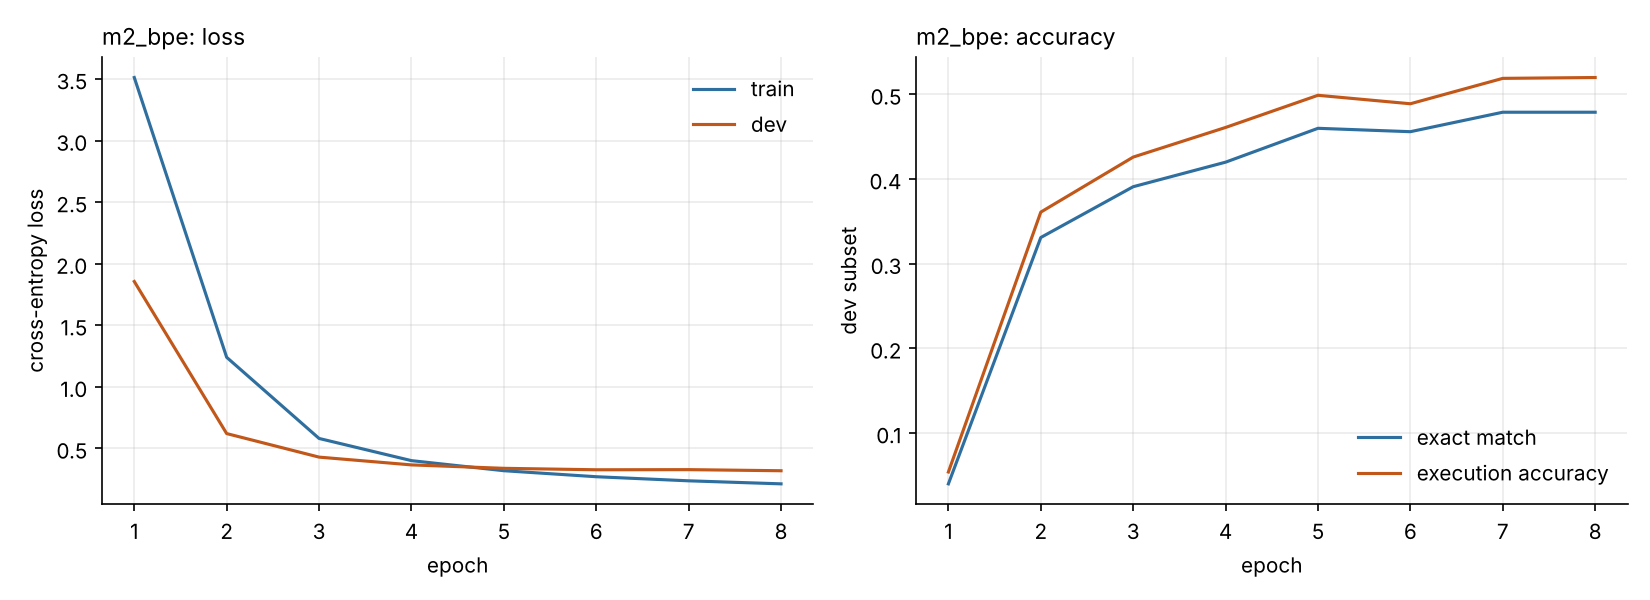

In [48]:
Image("results/m2_bpe/curves.png")

**What I observe.**

BPE learns fast. After 2 epochs, exact match on the dev subset is already 33% and execution accuracy is 36%. M2 had only 9% and 12% at the same epoch.

Loss goes down smoothly. Train loss falls from 3.5 to 0.21 and dev loss from 1.9 to 0.32. The dev loss flattens after epoch 5. The gap between the two (0.21 against 0.32) is much smaller than M2’s gap at epoch 25.

Accuracy rises to 48% exact match and 52% execution accuracy at epochs 7 and 8. The small dip at epoch 6 is noise, because the dev subset has only 1000 questions.

The model had not finished learning. The best epoch was the last one. I stopped at 8 epochs because of the compute limit.

On the full dev set, M2-BPE reaches 54.9% exact match and 61.1% execution accuracy with 6.8 million parameters. M3 reached 49.3% and 57.1% with 14.5 million.

Limit: M2-BPE had 8 epochs and M2 had 25. At the same epoch, BPE is ahead of M2 and M3 each time.

# Part C - Did it work?

## C1. The models side by side (dev set)

In [49]:
rows = []
for name in ["m1b", "m2", "m3", "m2_bpe"]:
    path = Path(f"results/{name}/metrics.json")
    if not path.exists():
        continue
    result = json.loads(path.read_text())
    dev = result["dev"]
    rows.append({"model": name, "parameters": f"{result['parameters']:,}", "vocabulary": f"{result['vocabulary']:,}",
                 "exact match": round(dev["exact_match"], 4), "execution accuracy": round(dev["execution_accuracy"], 4),
                 "valid format": round(dev["valid_format"], 4)})
comparison = pd.DataFrame(rows).set_index("model")
comparison.to_csv("results/phase5_copy_bpe/comparison.csv")
comparison

,parameters,vocabulary,exact match,execution accuracy,valid format
model,,,,,
m1b,"14,115,418","15,962",0.1644,0.2107,0.6990
m2,"14,509,402","15,962",0.4022,0.4486,0.8741
m3,"14,510,427","15,962",0.4934,0.5711,0.9217
m2_bpe,"6,830,168","5,976",0.5485,0.6114,0.8613


**What I observe.** Each improvement helps. Exact match goes from 16.4% (M1b) to 40.2% (M2, attention), to 49.3% (M3, copy), and to 54.9% (M2-BPE). Execution accuracy follows the same order: 21.1%, 44.9%, 57.1%, 61.1%.
Attention gives the biggest jump (+23.8 points). The decoder can look back at the question and the column names at each step.
Copy adds +9.1 points for only 1,025 extra parameters. M3 copies the words that the vocabulary cannot write.

BPE adds +5.5 points with less than half the parameters (6.8 million against 14.5 million), because its vocabulary is smaller (5,976 pieces).

BPE’s valid-format rate is lower (86.1% against 92.2% for M3). I will look at why in the error analysis in notebook 07.

Limits: one run per model, and different numbers of epochs (M2: 25, M3: 10, M2-BPE: 8). I check the small M3 / M2-BPE gap with confidence intervals in notebook 06.

## C2. The queries with an unknown word

The comparison above mixes two kinds of queries: those that need a word the plain vocabulary does not have, and the others. The copy mechanism and BPE
should help mostly on the first kind. I split the dev queries accordingly (using the vocabulary of the plain codec) and decode with each model.

In [50]:
from t2s.data.dataset import build_vocab
from t2s.evaluate import decode_examples
from t2s.eval.metrics import score

plain_vocab = build_vocab(splits["train"], min_freq=2)
dev = splits["dev"]
has_unknown = [any(t not in plain_vocab.stoi for t in target_tokens(e.query, e.header)) for e in dev]
print(f"dev queries with an unknown word in the output: {np.mean(has_unknown):.1%}")

rows = []
for name in ["m2", "m3", "m2_bpe"]:
    path = Path(CKPT_DIR) / name / "best.pt"
    if not path.exists():
        continue
    model, codec, cfg = load_checkpoint(path, device)
    outputs = decode_examples(model, dev, codec, device, cfg["data"]["max_src_len"], cfg["data"]["max_tgt_len"])
    _, predictions = score(dev, outputs, dev_executor)
    for label, flag in [("without an unknown word", False), ("with an unknown word", True)]:
        chosen = [p for p, h in zip(predictions, has_unknown) if h == flag]
        rows.append({"model": name, "dev queries": label, "number": len(chosen),
                     "exact match": round(np.mean([p.exact for p in chosen]), 4),
                     "execution accuracy": round(np.mean([p.correct for p in chosen]), 4)})
by_kind = pd.DataFrame(rows)
by_kind.to_csv("results/phase5_copy_bpe/by_unknown_word.csv", index=False)
by_kind

dev queries with an unknown word in the output: 38.0%


,model,dev queries,number,exact match,execution accuracy
0,m2,without an unknown word,5221,0.6487,0.7087
1,m2,with an unknown word,3200,0.0000,0.0244
2,m3,without an unknown word,5221,0.5464,0.6280
3,m3,with an unknown word,3200,0.4069,0.4781
4,m2_bpe,without an unknown word,5221,0.6051,0.6683
5,m2_bpe,with an unknown word,3200,0.4562,0.5188


**What I observe.** M2 cannot write an unknown word. On the 3,200 dev queries (38.0%) whose output contains a word outside the vocabulary, M2 gets 0.0% exact match. So its overall score cannot be higher than 62%, and its 40.2% overall comes only from the other 5,221 queries.

The copy mechanism and BPE fix this. On the same 3,200 queries, M3 reaches 40.7% exact match and M2-BPE reaches 45.6%.

On queries without an unknown word, M2 is the best (64.9%, against 54.6% for M3 and 60.5% for M2-BPE). The copy and BPE models lose some accuracy on easy queries. One likely reason is the training budget: M2 had 25 epochs, M3 had 10 and M2-BPE had 8. I cannot prove this from this table.

Overall, the gain on unknown words is much larger than the loss on the other queries, so M3 and M2-BPE are better on the whole dev set.
BPE is the best on queries with an unknown word (45.6% against 40.7% for M3). Its pieces can write any word.

## Summary of this notebook

**What I built:** the copy codec and the pointer-generator (M3), my own BPE (learning the merges, cutting words, the codec), and the configs to train
M3 and M2 with BPE.

**Checks:** the copy probabilities add up to 1; the gate controls the two ways of writing a word; the model learns to write words that are not in the
vocabulary; BPE reconstructs every word from its pieces.

**What I learned about the data:** 41.6% of the dev inputs contain a word that is not in the vocabulary, and a BPE vocabulary of 6,000 pieces covers
99% of the dev inputs completely, with a vocabulary about 2.7 times smaller than the word vocabulary.

**Next notebook:** `06_experiments.ipynb` studies the size of the model and the final results on the test set.